# Giai đoạn 2 (Ngày 3–4): Nâng trần & Nén ×4 Trực tiếp trên SOTA `ColQwen2.5-3B`

Notebook này tái sử dụng thẳng cache đã chạy ở Giai đoạn 1 trong `/content/drive/MyDrive/ViColPali_Stage1_Fresh` (không sửa file `results_s1_*.json` gốc) để giải quyết triệt để cả 2 nút thắt phát hiện ở Giai đoạn 1:

1. **Kiến trúc Model-Agnostic `DynamicMultiVectorAdapter` (~50K tham số):**
   - Bỏ hoàn toàn giả định lưới cứng `32×32` (của `ColPali v1.3`) để chạy mượt trên chuỗi patch độ dài động của **`ColQwen2.5-3B`** (`~733 vec/trang` → nén còn **`~184 vec/trang`**, giảm bộ nhớ index từ **`179.0 MB` xuống `~45 MB/1.000 trang`**).
   - **Sửa triệt để lỗi đường tắt `Query Gate` ở Giai đoạn 1:** Loại bỏ đặc trưng vị trí `f6_pos` (chỉ giữ 5 đặc trưng hình học bất biến vị trí) để cổng học đúng trọng số từ khóa ngữ nghĩa thay vì dồn vào token đầu câu (`<bos>`, `"Trong"`).
   - **Huấn luyện ổn định trên SOTA mạnh:** Đồng thích nghi 2 nhánh (*Dual-Tower Co-adaptation*) kết hợp `Warmup + Cosine LR (5e-4)`, **Strong-Teacher Self-KD** (từ `ColQwen2.5-3B` đang đạt `79.9` VI / `56.6` EN) và **Cosine Anchor** nhằm giữ nguyên hoặc vượt trần tiếng Việt mà không gây quên tiếng Anh (`EN DocVQA`).

2. **Tổ chức Dữ liệu Đa miền Sạch 100% (`V-Doc` + `5CD-AI/Viet-colpali_train_set-Gemini`):**
   - Chỉ dùng `5CD-AI` cho **tập Train bổ trợ** (đa dạng bảng biểu/slide/báo cáo PDF và câu hỏi tìm kiếm ngắn), **TUYỆT ĐỐI KHÔNG dùng để Val hay Test**.
   - Áp dụng **5 lớp chặn leakage**: (1) Loại bỏ hoàn toàn nguồn `docvqa`, (2) Lọc câu hỏi trùng văn bản chuẩn hóa với `V-Doc Test` + `EN DocVQA`, (3) Loại bỏ mọi ảnh trùng **MD5 hash 32×32** với `Test`, `Val`, `EN DocVQA` và `V-Doc Train`, (4) Giới hạn cân bằng tối đa `500` trang/nguồn, (5) Assert kiểm tra độc lập 0% giao nhau trước khi train.
   - Đánh giá trên **cùng 1 cặp thước đo sạch**: `V-Doc Test (1.067 trang)` và `EN DocVQA (500 trang)`.

In [ ]:
!pip install -q "colpali-engine>=0.3.18" pytesseract rank_bm25 timm einops matplotlib
!pip uninstall -y -q torchao
!pip install -q eva-decord || pip install -q decord || true

In [ ]:
import os, gc, glob, json, time, random, hashlib, tarfile, re, subprocess, shutil, copy, traceback
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download, login
from datasets import load_dataset
from torch.nn.utils.rnn import pad_sequence
from transformers import get_cosine_schedule_with_warmup

os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ---- Thư mục lưu trữ dùng chung cache Giai đoạn 1 (ghi kết quả Giai đoạn 2 ra file JSON riêng) ----
if os.path.isdir("/kaggle/working"):
    SAVE_DIR, DATA_DIR = "/kaggle/working/ViColPali_Stage1_Fresh", "/tmp/vdoc"
elif os.path.exists("/var/colab/hostname"):
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    SAVE_DIR, DATA_DIR = "/content/drive/MyDrive/ViColPali_Stage1_Fresh", "/content/vdoc"
    try:
        login(token=userdata.get("HF_TOKEN"))
    except Exception:
        print("Không có HF_TOKEN trong Colab Secrets (dataset V-Doc/ColQwen vẫn tải public bình thường; 5CD-AI có thể cần HF_TOKEN nếu repo yêu cầu).")
else:
    SAVE_DIR, DATA_DIR = "./ViColPali_Stage1_Fresh", "./vdoc"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# ---- Hằng số chia dữ liệu (giữ nguyên 100% với best.ipynb & Giai đoạn 1) ----
SEED = 42
N_SHARDS = 1
BLOCK, TEST_EVERY = 200, 10
MAX_TEST = 1500
DATA_SIZES = [1000]
N_TRAIN_PAGES, MAX_Q_PER_PAGE, N_VAL = 2000, 2, 300

# ---- Tham số huấn luyện Giai đoạn 2 ----
SEEDS = [0, 1, 2]
EPOCHS = 12
WARMUP_EPOCHS = 1
LR_ADAPTER = 5e-4
WEIGHT_DECAY = 2e-2
BQ = 32
HARD_NEG = 7
TEMP_CE = 0.10
TEMP_KD = 0.15
ANCHOR_W = 0.05
SCORE_CHUNK = 8
DOC_CHUNK = 64

# ---- Cấu hình trộn dữ liệu đa miền sạch 5CD-AI ----
RUN_5CD_MIX = True
N_5CD_PAGES = 1500
MAX_PER_5CD_SOURCE = 500
MAX_5CD_SCAN = 25000

# ---- Công tắc chạy từng phần ----
RUN_COLVINTERN = True
RUN_HIER_QWEN = True
RUN_QWEN_ADAPTERS = True
RUN_GATE_VIS = True
RUN_EN_CHECK = True
RUN_SLICE_ANALYSIS = True
RUN_PLOT = True
PREFER_FP16_ON_T4 = True

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0.0
VINTERN_IMG_BS = 8 if VRAM_GB >= 22 else 4
QWEN_IMG_BS = 4 if VRAM_GB >= 22 else 2

STAGE1_RES_PATH = f"{SAVE_DIR}/results_s{N_SHARDS}_b{BLOCK}_t{TEST_EVERY}_m{MAX_TEST}.json"
RES_PATH = f"{SAVE_DIR}/results_stage2_s{N_SHARDS}_b{BLOCK}_t{TEST_EVERY}_m{MAX_TEST}.json"

print("SAVE_DIR =", SAVE_DIR, "| DATA_DIR =", DATA_DIR)
if torch.cuda.is_available():
    print(
        f"GPU: {torch.cuda.get_device_name()} ({VRAM_GB:.1f} GB VRAM) | "
        f"bf16 supported: {torch.cuda.is_bf16_supported()} | "
        f"batch_size (Vintern/Qwen): {VINTERN_IMG_BS}/{QWEN_IMG_BS}"
    )
else:
    print("Đang chạy trên CPU")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Mounted at /content/drive
Không có HF_TOKEN trong Colab Secrets (dataset V-Doc/ColQwen vẫn tải public bình thường; 5CD-AI có thể cần HF_TOKEN nếu repo yêu cầu).
SAVE_DIR = /content/drive/MyDrive/ViColPali_Stage1_Fresh | DATA_DIR = /content/vdoc
GPU: NVIDIA L4 (23.7 GB VRAM) | bf16 supported: True | batch_size (Vintern/Qwen): 8/4


## 1. Tải `V-Doc` + `EN DocVQA` & Băm MD5 toàn bộ tập Test / Val / EN để chặn Leakage

In [ ]:
REPO = "trannhiem/TranNhiem-Vietnamese-DocumentImage-Reasoning"
jsonl = hf_hub_download(REPO, "data/vdoc.jsonl", repo_type="dataset", local_dir=DATA_DIR)
for s in range(N_SHARDS):
    marker = f"{DATA_DIR}/shards/images-{s:05d}.done"
    if os.path.exists(marker):
        continue
    tar_path = hf_hub_download(REPO, f"shards/images-{s:05d}.tar", repo_type="dataset", local_dir=DATA_DIR)
    with tarfile.open(tar_path) as t:
        t.extractall(DATA_DIR, filter="data")
    os.remove(tar_path)
    open(marker, "w").close()

records, skipped = [], 0
with open(jsonl, encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        path = os.path.join(DATA_DIR, r["image"])
        if not os.path.exists(path):
            continue
        if not str(r["id"]).isdigit():
            skipped += 1
            continue
        qs = [t["value"].strip() for t in r["conversations"]
              if t["from"] == "human" and isinstance(t["value"], str) and len(t["value"].strip()) > 10]
        if qs:
            records.append({"id": int(r["id"]), "path": path, "qs": qs})
print(f"{len(records)} trang V-Doc hợp lệ (bỏ {skipped} trang có id không phải số)")

def img_hash_pil(im):
    return hashlib.md5(im.convert("L").resize((32, 32)).tobytes()).hexdigest()

def img_hash(p):
    with Image.open(p) as im:
        im.draft("L", (64, 64))
        return img_hash_pil(im)

for r in tqdm(records, desc="hash ảnh V-Doc"):
    r["h"] = img_hash(r["path"])

records.sort(key=lambda r: r["id"])
is_test = lambda r: (r["id"] // BLOCK) % TEST_EVERY == 0
test_pages, test_h = [], set()
for r in records:
    if is_test(r) and r["h"] not in test_h:
        test_h.add(r["h"])
        test_pages.append(r)
random.Random(SEED).shuffle(test_pages)
test_pages = test_pages[:MAX_TEST]
test_h = {r["h"] for r in test_pages}
train_pages = [r for r in records if not is_test(r) and r["h"] not in test_h]

TEST_DOCS = [r["path"] for r in test_pages]
TEST_Q = [r["qs"][0] for r in test_pages]
TEST_T = list(range(len(test_pages)))

rng = random.Random(SEED)
is_val = lambda r: (r["id"] // BLOCK) % TEST_EVERY == 1
val_pages, val_h = [], set()
for r in train_pages:
    if is_val(r) and r["h"] not in val_h:
        val_h.add(r["h"])
        val_pages.append(r)
rng.shuffle(val_pages)
val_pages = val_pages[:N_VAL]
val_h = {r["h"] for r in val_pages}

sg_pages = [r for r in train_pages if not is_val(r) and r["h"] not in val_h]
rng.shuffle(sg_pages)
sg_pages = sg_pages[:N_TRAIN_PAGES]
tr_q, tr_t = [], []
for i, r in enumerate(sg_pages):
    for q in r["qs"][:MAX_Q_PER_PAGE]:
        tr_q.append(q)
        tr_t.append(i)
VAL_T = list(range(len(val_pages)))

vdoc_tr_h = {r["h"] for r in sg_pages}
assert vdoc_tr_h.isdisjoint(val_h) and vdoc_tr_h.isdisjoint(test_h) and val_h.isdisjoint(test_h), "Rò rỉ hash V-Doc!"
assert {r["id"] for r in train_pages}.isdisjoint({r["id"] for r in test_pages}), "Rò rỉ id V-Doc!"

# Bộ kiểm tra tiếng Anh: ViDoRe DocVQA
EN_DOCS, EN_Q, EN_T = [], [], []
en_h = set()
if RUN_EN_CHECK:
    idx = {}
    os.makedirs(f"{DATA_DIR}/en", exist_ok=True)
    for row in load_dataset("vidore/docvqa_test_subsampled", split="test"):
        if row["image_filename"] not in idx:
            p = f"{DATA_DIR}/en/{len(EN_DOCS)}.png"
            row["image"].save(p)
            idx[row["image_filename"]] = len(EN_DOCS)
            EN_DOCS.append(p)
            en_h.add(img_hash(p))
        if row["query"]:
            EN_Q.append(row["query"])
            EN_T.append(idx[row["image_filename"]])

norm_q = lambda s: re.sub(r"\s+", " ", str(s).strip().lower())
forbidden_q_norm = {norm_q(q) for q in (TEST_Q + EN_Q)}
forbidden_hashes = test_h | val_h | en_h | vdoc_tr_h

print(f"V-Doc -> Train: {len(sg_pages)} trang ({len(tr_q)} câu) | Val: {len(val_pages)} | Test: {len(TEST_Q)} trang")
print(f"EN DocVQA -> {len(EN_Q)} câu / {len(EN_DOCS)} trang | Tập hash cấm leakage: {len(forbidden_hashes)}")
print("Khớp TEST_Q[0]:", TEST_Q[0])

data/vdoc.jsonl: reconstructing file:   0%|          |  0.00B / 1.10GB            

data/vdoc.jsonl: downloading bytes:           |  0.00B            

shards/images-00000.tar: reconstructing file:   0%|          |  0.00B / 1.61GB            

shards/images-00000.tar: downloading bytes:           |  0.00B            

11000 trang V-Doc hợp lệ (bỏ 0 trang có id không phải số)


hash ảnh V-Doc:   0%|          | 0/11000 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  292MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

V-Doc -> Train: 2000 trang (4000 câu) | Val: 300 | Test: 1067 trang
EN DocVQA -> 500 câu / 500 trang | Tập hash cấm leakage: 3850
Khớp TEST_Q[0]: Trong Ví dụ 1 (Hình 4.49), với các điều kiện AB vuông góc với BC, AD vuông góc với CD và AC cắt BD tại E, góc BAC bằng góc DAC, hãy chứng minh rằng tam giác BAC bằng tam giác DAC và AC vuông góc với BD tại E.


## 2. Tổ chức Dữ liệu Đa miền Sạch 100% (`5CD-AI/Viet-colpali_train_set-Gemini`)

> **Nguyên tắc học thuật:** `5CD-AI/Viet-colpali_train_set-Gemini` là bản dịch Việt hóa từ tập train của ColPali gốc, vì vậy **CHỈ được phép dùng bổ trợ cho nhánh Train** để đa dạng hóa miền dữ liệu (bảng biểu, slide, báo cáo PDF, câu hỏi ngắn) — **tuyệt đối KHÔNG dùng để Val hay Test**.

Hàm `filter_5cd_stream` thực thi **5 lớp lọc Leakage nghiêm ngặt**:
1. **Loại bỏ hoàn toàn nguồn `docvqa`:** Tránh giao thoa phân bố/mẫu ảnh với tập kiểm định chéo `EN DocVQA`.
2. **Lọc chất lượng & chống trùng văn bản câu hỏi:** Loại query `< 12` ký tự hoặc trùng văn bản chuẩn hóa với bất kỳ câu hỏi nào trong `V-Doc Test` hoặc `EN DocVQA`.
3. **Chặn trùng ảnh MD5 (32×32):** Loại bỏ bất kỳ trang nào trùng hash với `Test`, `Val`, `EN DocVQA`, `V-Doc Train` và loại trùng lặp nội bộ trong `5CD-AI`.
4. **Cân bằng phân tầng theo nguồn (`source`):** Giới hạn tối đa `500` trang/nguồn để tránh một miền tổng hợp áp đảo.
5. **Kiểm định khẳng định (`assert`) sau lọc:** Xác minh 0% giao nhau cả về hash ảnh lẫn văn bản query trước khi đưa vào huấn luyện.

In [ ]:
def filter_5cd_stream(stream_iter, forbidden_hashes, forbidden_q_norm,
                      max_pages=1500, max_per_source=500, max_scan=25000, save_img_dir=None):
    stats = {
        "scanned": 0, "accepted": 0,
        "rej_docvqa": 0, "rej_bad_q": 0, "rej_q_leak": 0,
        "rej_source_cap": 0, "rej_bad_img": 0, "rej_hash_leak": 0, "rej_dup_5cd": 0,
    }
    accepted = []
    source_counts = Counter()
    seen_5cd_h = set()
    if save_img_dir is not None:
        os.makedirs(save_img_dir, exist_ok=True)

    for row in stream_iter:
        if stats["scanned"] >= max_scan or stats["accepted"] >= max_pages:
            break
        stats["scanned"] += 1

        src = str(row.get("source") or "unknown").strip() or "unknown"
        if "docvqa" in src.lower():
            stats["rej_docvqa"] += 1
            continue

        q = row.get("query")
        if not isinstance(q, str) or len(q.strip()) < 12:
            stats["rej_bad_q"] += 1
            continue
        qn = norm_q(q)
        if qn in forbidden_q_norm:
            stats["rej_q_leak"] += 1
            continue

        if source_counts[src] >= max_per_source:
            stats["rej_source_cap"] += 1
            continue

        im = row.get("image")
        if im is None:
            stats["rej_bad_img"] += 1
            continue
        try:
            rgb = im.convert("RGB") if isinstance(im, Image.Image) else Image.open(im).convert("RGB")
        except Exception:
            stats["rej_bad_img"] += 1
            continue

        h = img_hash_pil(rgb)
        if h in forbidden_hashes:
            stats["rej_hash_leak"] += 1
            continue
        if h in seen_5cd_h:
            stats["rej_dup_5cd"] += 1
            continue

        seen_5cd_h.add(h)
        source_counts[src] += 1
        idx_out = stats["accepted"]
        stats["accepted"] += 1

        rec = {"query": q.strip(), "source": src, "h": h}
        if save_img_dir is not None:
            out_p = os.path.join(save_img_dir, f"mix5cd_{idx_out:05d}.jpg")
            rgb.save(out_p, quality=95)
            rec["path"] = out_p
        else:
            rec["image"] = rgb
        accepted.append(rec)

    return accepted, stats, dict(source_counts)

MIX5CD_PAGES = []
MIX5CD_AUDIT = None
mix_emb_cache = f"{SAVE_DIR}/colqwen25_v02_5cd_emb_{N_5CD_PAGES}.pt"
mix_audit_path = f"{SAVE_DIR}/mix5cd_audit_{N_5CD_PAGES}.json"
mix_img_dir = f"{DATA_DIR}/mix5cd_{N_5CD_PAGES}"

if RUN_5CD_MIX:
    if os.path.exists(mix_emb_cache) and os.path.exists(mix_audit_path):
        MIX5CD_AUDIT = json.load(open(mix_audit_path, encoding="utf-8"))
        MIX5CD_PAGES = MIX5CD_AUDIT["pages"]
        print(f"Nạp metadata & kiểm định 5CD-AI đã cache ({len(MIX5CD_PAGES)} trang) từ:", mix_audit_path)
    else:
        try:
            print("Đang stream & lọc sạch tập 5CD-AI/Viet-colpali_train_set-Gemini...")
            ds_5cd = load_dataset("5CD-AI/Viet-colpali_train_set-Gemini", split="train", streaming=True)
            MIX5CD_PAGES, mix_stats, mix_sources = filter_5cd_stream(
                ds_5cd,
                forbidden_hashes=forbidden_hashes,
                forbidden_q_norm=forbidden_q_norm,
                max_pages=N_5CD_PAGES,
                max_per_source=MAX_PER_5CD_SOURCE,
                max_scan=MAX_5CD_SCAN,
                save_img_dir=mix_img_dir,
            )
            MIX5CD_AUDIT = {
                "stats": mix_stats,
                "source_counts": mix_sources,
                "pages": [{"query": r["query"], "source": r["source"], "h": r["h"], "path": r["path"]} for r in MIX5CD_PAGES],
            }
            with open(mix_audit_path, "w", encoding="utf-8") as f:
                json.dump(MIX5CD_AUDIT, f, ensure_ascii=False)
        except Exception as exc:
            print(f"⚠ Không tải được 5CD-AI ({exc}).")
            print("  Nếu repo yêu cầu quyền truy cập: hãy vào trang HuggingFace của 5CD-AI bấm Accept và thêm HF_TOKEN vào Colab Secrets.")
            print("  Notebook sẽ tự động bỏ qua nhánh Mix và chạy trọn vẹn các thực nghiệm Single-Domain V-Doc.")
            MIX5CD_PAGES, MIX5CD_AUDIT = [], None

if MIX5CD_AUDIT is not None and len(MIX5CD_PAGES) > 0:
    mix_h = {r["h"] for r in MIX5CD_PAGES}
    mix_q_norm = {norm_q(r["query"]) for r in MIX5CD_PAGES}
    assert mix_h.isdisjoint(forbidden_hashes), "PHÁT HIỆN RÒ RỈ HASH ẢNH từ 5CD-AI!"
    assert mix_q_norm.isdisjoint(forbidden_q_norm), "PHÁT HIỆN RÒ RỈ CÂU HỎI từ 5CD-AI!"
    assert all("docvqa" not in str(r["source"]).lower() for r in MIX5CD_PAGES), "PHÁT HIỆN NGUỒN docvqa lọt vào!"
    print("Audit lọc 5CD-AI (0% leakage đã assert):", MIX5CD_AUDIT["stats"])
    print("Phân bố nguồn 5CD-AI đã giữ lại:", MIX5CD_AUDIT["source_counts"])

Đang stream & lọc sạch tập 5CD-AI/Viet-colpali_train_set-Gemini...


README.md:   0%|          | 0.00/6.01k [00:00<?, ?B/s]

⚠ Không tải được 5CD-AI (Dataset '5CD-AI/Viet-colpali_train_set-Gemini' is a gated dataset on the Hub. You must be authenticated to access it.).
  Nếu repo yêu cầu quyền truy cập: hãy vào trang HuggingFace của 5CD-AI bấm Accept và thêm HF_TOKEN vào Colab Secrets.
  Notebook sẽ tự động bỏ qua nhánh Mix và chạy trọn vẹn các thực nghiệm Single-Domain V-Doc.


## 3. Hàm đánh giá, Ragged MaxSim hỗ trợ Gate & Nạp kết quả Giai đoạn 1

In [ ]:
KEYS = ["nDCG@5", "R@1", "R@5", "MRR@10"]
MB_PER_1K = lambda vec, dim=128: vec * dim * 2 * 1000 / 2**20

def load_img(x):
    return (x if isinstance(x, Image.Image) else Image.open(x)).convert("RGB")

def to_dev(batch, model, cast_mask=False):
    p = next(model.parameters())
    dev, dt = p.device, p.dtype
    out = {}
    for k, v in batch.items():
        if k == "labels":
            continue
        if not torch.is_tensor(v):
            out[k] = v
            continue
        is_float = v.is_floating_point() or (cast_mask and k == "attention_mask")
        out[k] = v.to(dev, dtype=dt) if is_float else v.to(dev)
    return out

@torch.no_grad()
def encode(model, proc, items, is_image, bs=4, cast_mask=False):
    embs = []
    for i in tqdm(range(0, len(items), bs), desc="pages" if is_image else "queries", leave=False):
        chunk = items[i:i + bs]
        b = proc.process_images([load_img(x) for x in chunk]) if is_image else proc.process_queries(chunk)
        b = to_dev(b, model, cast_mask=cast_mask)
        e = model(**b)
        if isinstance(e, (tuple, list)):
            e = e[0]
        elif hasattr(e, "embeddings"):
            e = e.embeddings
        has_mask = ("attention_mask" in b) and torch.is_tensor(b["attention_mask"]) and (e.shape[1] == b["attention_mask"].shape[1])
        if has_mask:
            for x, m in zip(e, b["attention_mask"]):
                embs.append(x[m.bool()].to("cpu", torch.bfloat16))
        else:
            for x in e:
                valid = x.float().norm(dim=-1) > 1e-4
                embs.append((x[valid] if valid.any() else x).to("cpu", torch.bfloat16))
    return embs

def _pad_with_mask(seq_list):
    lens = [x.shape[0] for x in seq_list]
    padded = pad_sequence([x.float() for x in seq_list], batch_first=True)
    idx = torch.arange(padded.shape[1])[None, :]
    mask = idx < torch.tensor(lens)[:, None]
    return padded, mask

@torch.no_grad()
def score_ragged_maxsim(Q_list, D_list, G_list=None, q_chunk=32, d_chunk=128, device=DEVICE):
    """Tính MaxSim cho danh sách tensor độ dài động, có hỗ trợ trọng số cổng G_list."""
    use_cuda = str(device).startswith("cuda") and torch.cuda.is_available()
    comp_dt = torch.bfloat16 if (use_cuda and torch.cuda.is_bf16_supported()) else (torch.float16 if use_cuda else torch.float32)
    out = torch.empty(len(Q_list), len(D_list), dtype=torch.float32)
    for i in range(0, len(Q_list), q_chunk):
        q_pad, q_mask = _pad_with_mask(Q_list[i:i + q_chunk])
        q_dev = q_pad.to(device, dtype=comp_dt)
        qm_dev = q_mask.to(device)
        if G_list is not None:
            g_pad = pad_sequence([g.float() for g in G_list[i:i + q_chunk]], batch_first=True).to(device)
            g_eff = g_pad * qm_dev.float()
        else:
            g_eff = qm_dev.float()
        for j in range(0, len(D_list), d_chunk):
            d_pad, d_mask = _pad_with_mask(D_list[j:j + d_chunk])
            d_dev = d_pad.to(device, dtype=comp_dt)
            dm_dev = d_mask.to(device)
            sim = torch.einsum("bqd,cpd->bcqp", q_dev, d_dev).float()
            sim = sim.masked_fill(~dm_dev[None, :, None, :], -1e9)
            max_sim = sim.amax(dim=-1) * g_eff[:, None, :]
            out[i:i + q_chunk, j:j + d_chunk] = max_sim.sum(dim=-1).cpu()
    return out

def ranks_from_scores(S, targets):
    S = torch.as_tensor(S, dtype=torch.float32)
    t = torch.as_tensor(targets)
    pos = S[torch.arange(len(t)), t]
    return (S >= pos[:, None]).sum(1).numpy()

def per_query(r, key):
    r = np.asarray(r, dtype=float)
    return {
        "nDCG@5": np.where(r <= 5, 1 / np.log2(r + 1), 0),
        "R@1": (r <= 1) * 1.0,
        "R@5": (r <= 5) * 1.0,
        "MRR@10": np.where(r <= 10, 1 / r, 0),
    }[key] * 100

def metrics(r):
    return {k: per_query(r, k).mean() for k in KEYS}

def boot(v, n=2000):
    return v[np.random.default_rng(0).integers(0, len(v), (n, len(v)))].mean(1)

def ci(r, key="nDCG@5"):
    return np.percentile(boot(per_query(r, key)), [2.5, 97.5])

def paired_p(ra, rb, key="nDCG@5"):
    b = boot(per_query(ra, key) - per_query(rb, key))
    return min(1.0, 2 * min((b <= 0).mean(), (b >= 0).mean()))

def vec_per_page(D):
    return float(np.mean([len(x) for x in D]))

def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def sync_ms(fn, n):
    use_cuda = torch.cuda.is_available()
    fn()
    if use_cuda:
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = fn()
    if use_cuda:
        torch.cuda.synchronize()
    return out, (time.perf_counter() - t0) * 1000 / n

# ---- Unit tests nhanh cho score_ragged_maxsim (có và không có G_list) ----
_rng = torch.Generator().manual_seed(0)
_q_rag = [F.normalize(torch.randn(3, 16, generator=_rng), dim=-1), F.normalize(torch.randn(7, 16, generator=_rng), dim=-1)]
_d_rag = [F.normalize(torch.randn(5, 16, generator=_rng), dim=-1), F.normalize(torch.randn(11, 16, generator=_rng), dim=-1)]
_g_rag = [torch.tensor([0.5, 1.8, 0.7]), torch.linspace(0.6, 1.4, 7)]
_s_no_g = score_ragged_maxsim(_q_rag, _d_rag, G_list=None, q_chunk=1, d_chunk=1, device="cpu")
_s_no_g_ref = torch.tensor([[(q @ d.T).max(dim=-1).values.sum().item() for d in _d_rag] for q in _q_rag])
assert torch.allclose(_s_no_g, _s_no_g_ref, atol=1e-3)
_s_with_g = score_ragged_maxsim(_q_rag, _d_rag, G_list=_g_rag, q_chunk=1, d_chunk=1, device="cpu")
_s_with_g_ref = torch.tensor([[((q @ d.T).max(dim=-1).values * g).sum().item() for d in _d_rag] for q, g in zip(_q_rag, _g_rag)])
assert torch.allclose(_s_with_g, _s_with_g_ref, atol=1e-3)

# ---- Nạp RESULTS (ưu tiên Stage 2 nếu có, không thì kế thừa Stage 1 read-only) ----
if os.path.exists(RES_PATH):
    RESULTS = json.load(open(RES_PATH, encoding="utf-8"))
elif os.path.exists(STAGE1_RES_PATH):
    RESULTS = json.load(open(STAGE1_RES_PATH, encoding="utf-8"))
    with open(RES_PATH, "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, ensure_ascii=False)
else:
    RESULTS = {}

def save_result(name, **kw):
    RESULTS[name] = {k: (None if v is None else np.asarray(v).tolist()) for k, v in kw.items()}
    with open(RES_PATH, "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, ensure_ascii=False)

ocr_path = f"{SAVE_DIR}/ocr_test_{len(TEST_DOCS)}.json"
OCR_TEXTS = json.load(open(ocr_path, encoding="utf-8")) if os.path.exists(ocr_path) else None
print(f"Đã nạp {len(RESULTS)} mốc kết quả sẵn có:", list(RESULTS))

Đã nạp 13 mốc kết quả sẵn có: ['BM25 + OCR (Tesseract vie)', 'ColPali 3B đầy đủ (zero-shot)', 'Hierarchical pooling ×4 (không train, CPU)', 'A: gộp dải 2D (chưa train)', 'B: + bộ gộp 2D học được (KD)', 'B2: + bộ gộp 2D học được (không KD)', 'C1: gộp 2D (chưa train) + chỉ Bi-Subword', 'C2: gộp 2D (chưa train) + chỉ Query Gate', 'C3: gộp 2D (chưa train) + Bi-Subword & Gate', 'C: + cổng query (không KD)', 'Full SG-ColPali (cổng + KD)', 'Upper-bound: ColPali 1031 + Query Module (không nén)', 'SOTA: ColQwen2.5-3B (zero-shot)']


## 4. Bổ sung `ColVintern-1B-v1`, Cache Embedding `ColQwen2.5-3B` & `Hierarchical Pooling ×4`

- **Cảnh báo công bằng về `ColVintern-1B-v1`:** `ColVintern-1B-v1` do `5CD-AI` phát hành và được train trên hệ sinh thái VQA tiếng Việt (có gốc từ `Viet-Doc-VQA-II`), nên có khả năng đã tiếp xúc một phần nguồn ảnh của `V-Doc`; trong khi `ColQwen2.5-3B` (`vidore/colqwen2.5-v0.2`) là **zero-shot sạch 100%** trên dữ liệu này.
- Tự động tái sử dụng file `colqwen25_v02_test_emb.pt` từ Giai đoạn 1 nếu đã có, chỉ encode thêm phần `train (2.000)`, `val (300)` và `5CD-AI` (nếu bật Mix).

In [ ]:
def load_model_safe(loader_fn, proc, sample_imgs, sample_qs, cast_mask=False):
    if torch.cuda.is_available():
        if PREFER_FP16_ON_T4 and not torch.cuda.is_bf16_supported():
            dtypes = [torch.float16, torch.bfloat16]
        else:
            dtypes = [torch.bfloat16]
    else:
        dtypes = [torch.float32]

    last_err = None
    for dt in dtypes:
        m = None
        try:
            print(f"  Thử nạp model với dtype={dt}...")
            m = loader_fn(dt).eval()
            out_d = encode(m, proc, sample_imgs[:2], True, bs=2, cast_mask=cast_mask)
            out_q = encode(m, proc, sample_qs[:2], False, bs=2, cast_mask=cast_mask)
            if all(torch.isfinite(x).all() and x.float().norm(dim=-1).mean() > 1e-3 for x in out_d + out_q):
                print(f"  ✓ Sanity check thành công với dtype={dt} | shape trang mẫu: {tuple(out_d[0].shape)}")
                return m, dt
            raise RuntimeError(f"Sanity check phát hiện NaN/Inf hoặc vector 0 với dtype={dt}")
        except Exception as exc:
            last_err = exc
            print(f"  ✗ Lỗi với dtype={dt}: {exc}")
            if m is not None:
                del m
            free()
    raise RuntimeError(f"Không nạp được model. Lỗi cuối: {last_err}")

# 1. Bổ sung ColVintern-1B-v1 (zero-shot) nếu chưa có trong RESULTS
NAME_VINTERN = "SOTA: ColVintern-1B-v1 (zero-shot)"
if RUN_COLVINTERN and NAME_VINTERN not in RESULTS:
    vintern_cache = f"{SAVE_DIR}/colvintern_1b_v1_test_emb.pt"
    try:
        if os.path.exists(vintern_cache):
            pack = torch.load(vintern_cache, map_location="cpu")
            Dv, Qv, Dv_en, Qv_en = pack["D_test"], pack["Q_test"], pack.get("D_en"), pack.get("Q_en")
            enc_s, emb_dim = pack.get("encode_s_per_page"), int(pack.get("embed_dim", Dv[0].shape[-1]))
        else:
            from transformers import AutoModel, AutoProcessor
            print("\n>>> Đang chạy benchmark:", NAME_VINTERN)
            proc_v = AutoProcessor.from_pretrained("5CD-AI/ColVintern-1B-v1", trust_remote_code=True)
            model_v, used_dt = load_model_safe(
                lambda dt: AutoModel.from_pretrained("5CD-AI/ColVintern-1B-v1", trust_remote_code=True, torch_dtype=dt, device_map=DEVICE),
                proc_v, TEST_DOCS[:2], TEST_Q[:2], cast_mask=True,
            )
            t0 = time.perf_counter()
            Dv = encode(model_v, proc_v, TEST_DOCS, True, bs=VINTERN_IMG_BS, cast_mask=True)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            enc_s = (time.perf_counter() - t0) / len(TEST_DOCS)
            Qv = encode(model_v, proc_v, TEST_Q, False, bs=16, cast_mask=True)
            emb_dim = int(Dv[0].shape[-1])
            Dv_en = Qv_en = None
            if RUN_EN_CHECK:
                Dv_en = encode(model_v, proc_v, EN_DOCS, True, bs=VINTERN_IMG_BS, cast_mask=True)
                Qv_en = encode(model_v, proc_v, EN_Q, False, bs=16, cast_mask=True)
            torch.save({
                "D_test": Dv, "Q_test": Qv, "D_en": Dv_en, "Q_en": Qv_en,
                "encode_s_per_page": enc_s, "embed_dim": emb_dim, "dtype": str(used_dt),
            }, vintern_cache)
            del model_v, proc_v
            free()

        vi_r = ranks_from_scores(score_ragged_maxsim(Qv, Dv), TEST_T)
        en_r = ranks_from_scores(score_ragged_maxsim(Qv_en, Dv_en), EN_T) if (RUN_EN_CHECK and Dv_en is not None) else None
        save_result(
            NAME_VINTERN, vi=vi_r, en=en_r,
            vec_per_page=vec_per_page(Dv), embed_dim=emb_dim, encode_s_per_page=enc_s,
            device=torch.cuda.get_device_name() if torch.cuda.is_available() else "CPU",
        )
        print("  ColVintern VI:", {k: round(float(v), 2) for k, v in metrics(vi_r).items()})
        del Dv, Qv, Dv_en, Qv_en
        free()
    except Exception as exc:
        print(f"✗ Bỏ qua {NAME_VINTERN} do lỗi: {exc}")
        traceback.print_exc()
        free()

# 2. Nạp / Encode toàn bộ embedding ColQwen2.5-3B (test/en + tr/val + 5cd)
qwen_test_cache = f"{SAVE_DIR}/colqwen25_v02_test_emb.pt"
qwen_trval_cache = f"{SAVE_DIR}/colqwen25_v02_trval_s{N_SHARDS}_tr{N_TRAIN_PAGES}x{MAX_Q_PER_PAGE}_v{N_VAL}.pt"

need_test = not os.path.exists(qwen_test_cache)
need_trval = not os.path.exists(qwen_trval_cache)
need_5cd = RUN_5CD_MIX and len(MIX5CD_PAGES) > 0 and not os.path.exists(mix_emb_cache)

if need_test or need_trval or need_5cd:
    from colpali_engine.models import ColQwen2_5, ColQwen2_5_Processor
    print("\n>>> Nạp ColQwen2.5-3B để encode phần còn thiếu:",
          {"test": need_test, "trval": need_trval, "5cd": need_5cd})
    proc_q = ColQwen2_5_Processor.from_pretrained("vidore/colqwen2.5-v0.2")
    model_q, used_dt = load_model_safe(
        lambda dt: ColQwen2_5.from_pretrained("vidore/colqwen2.5-v0.2", torch_dtype=dt, device_map=DEVICE),
        proc_q, TEST_DOCS[:2], TEST_Q[:2], cast_mask=False,
    )

    if need_test:
        t0 = time.perf_counter()
        D_test = encode(model_q, proc_q, TEST_DOCS, True, bs=QWEN_IMG_BS)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        enc_s = (time.perf_counter() - t0) / len(TEST_DOCS)
        Q_test = encode(model_q, proc_q, TEST_Q, False, bs=16)
        D_en = encode(model_q, proc_q, EN_DOCS, True, bs=QWEN_IMG_BS) if RUN_EN_CHECK else None
        Q_en = encode(model_q, proc_q, EN_Q, False, bs=16) if RUN_EN_CHECK else None
        torch.save({
            "D_test": D_test, "Q_test": Q_test, "D_en": D_en, "Q_en": Q_en,
            "encode_s_per_page": enc_s, "embed_dim": int(D_test[0].shape[-1]), "dtype": str(used_dt),
        }, qwen_test_cache)

    if need_trval:
        t0 = time.perf_counter()
        D_tr = encode(model_q, proc_q, [r["path"] for r in sg_pages], True, bs=QWEN_IMG_BS)
        Q_tr = encode(model_q, proc_q, tr_q, False, bs=32)
        D_val = encode(model_q, proc_q, [r["path"] for r in val_pages], True, bs=QWEN_IMG_BS)
        Q_val = encode(model_q, proc_q, [r["qs"][0] for r in val_pages], False, bs=32)
        torch.save({"D_tr": D_tr, "Q_tr": Q_tr, "D_val": D_val, "Q_val": Q_val}, qwen_trval_cache)
        print(f"  Đã cache xong ColQwen2.5 train/val trong {(time.perf_counter() - t0)/60:.1f} phút")

    if need_5cd:
        t0 = time.perf_counter()
        D_5cd = encode(model_q, proc_q, [r["path"] for r in MIX5CD_PAGES], True, bs=QWEN_IMG_BS)
        Q_5cd = encode(model_q, proc_q, [r["query"] for r in MIX5CD_PAGES], False, bs=32)
        torch.save({"D_5cd": D_5cd, "Q_5cd": Q_5cd}, mix_emb_cache)
        print(f"  Đã cache xong ColQwen2.5 5CD-AI ({len(D_5cd)} trang) trong {(time.perf_counter() - t0)/60:.1f} phút")

    del model_q, proc_q
    free()

pack_test = torch.load(qwen_test_cache, map_location="cpu")
D_test, Q_test = pack_test["D_test"], pack_test["Q_test"]
D_en, Q_en = pack_test.get("D_en"), pack_test.get("Q_en")

pack_trval = torch.load(qwen_trval_cache, map_location="cpu")
D_tr, Q_tr = pack_trval["D_tr"], pack_trval["Q_tr"]
D_val, Q_val = pack_trval["D_val"], pack_trval["Q_val"]

D_5cd = Q_5cd = None
if RUN_5CD_MIX and os.path.exists(mix_emb_cache) and len(MIX5CD_PAGES) > 0:
    pack_5cd = torch.load(mix_emb_cache, map_location="cpu")
    D_5cd, Q_5cd = pack_5cd["D_5cd"], pack_5cd["Q_5cd"]

NAME_QWEN = "SOTA: ColQwen2.5-3B (zero-shot)"
if NAME_QWEN not in RESULTS:
    vi_r = ranks_from_scores(score_ragged_maxsim(Q_test, D_test), TEST_T)
    en_r = ranks_from_scores(score_ragged_maxsim(Q_en, D_en), EN_T) if (RUN_EN_CHECK and D_en is not None) else None
    save_result(
        NAME_QWEN, vi=vi_r, en=en_r,
        vec_per_page=vec_per_page(D_test), embed_dim=int(D_test[0].shape[-1]),
        encode_s_per_page=pack_test.get("encode_s_per_page"),
        device=torch.cuda.get_device_name() if torch.cuda.is_available() else "CPU",
    )

# 3. Baseline nén chính thức trên ColQwen2.5: Hierarchical Token Pooling ×4 (CPU)
NAME_HIER_Q = "ColQwen2.5 + Hierarchical pooling ×4 (không train, CPU)"
if RUN_HIER_QWEN and NAME_HIER_Q not in RESULTS:
    from colpali_engine.compression.token_pooling import HierarchicalTokenPooler
    pooler = HierarchicalTokenPooler()
    t0 = time.perf_counter()
    Dp_vi = pooler.pool_embeddings([x.float() for x in D_test], pool_factor=4, num_workers=os.cpu_count())
    ms_h = (time.perf_counter() - t0) * 1000 / len(D_test)
    Dp_vi = [x.to(torch.bfloat16) for x in Dp_vi]
    vi_r = ranks_from_scores(score_ragged_maxsim(Q_test, Dp_vi), TEST_T)
    en_r = None
    if RUN_EN_CHECK and D_en is not None and Q_en is not None:
        Dp_en = [x.to(torch.bfloat16) for x in pooler.pool_embeddings([x.float() for x in D_en], pool_factor=4, num_workers=os.cpu_count())]
        en_r = ranks_from_scores(score_ragged_maxsim(Q_en, Dp_en), EN_T)
        del Dp_en
    save_result(
        NAME_HIER_Q, vi=vi_r, en=en_r,
        vec_per_page=vec_per_page(Dp_vi), embed_dim=int(D_test[0].shape[-1]),
        ms_per_page=ms_h, device=f"CPU x{os.cpu_count()}",
    )
    print(f"Hierarchical ×4 trên ColQwen2.5: vec/trang={vec_per_page(Dp_vi):.1f} | {ms_h:.1f} ms/trang | VI:",
          {k: round(float(v), 2) for k, v in metrics(vi_r).items()})
    del Dp_vi
    free()

print(f"Embedding sẵn sàng -> D_tr: {len(D_tr)} | D_val: {len(D_val)} | D_test: {len(D_test)} | D_5cd: {len(D_5cd) if D_5cd else 0}")


>>> Đang chạy benchmark: SOTA: ColVintern-1B-v1 (zero-shot)


preprocessor_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.06k [00:00<?, ?B/s]

processing_colinternvl2.py:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

conversation.py:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/5CD-AI/ColVintern-1B-v1:
- conversation.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


... (50 outputs left out)

queries:   0%|          | 0/125 [00:00<?, ?it/s]

pages:   0%|          | 0/75 [00:00<?, ?it/s]

queries:   0%|          | 0/10 [00:00<?, ?it/s]

  Đã cache xong ColQwen2.5 train/val trong 16.6 phút
Hierarchical ×4 trên ColQwen2.5: vec/trang=182.6 | 90.1 ms/trang | VI: {'nDCG@5': 78.5, 'R@1': 69.63, 'R@5': 85.38, 'MRR@10': 76.78}
Embedding sẵn sàng -> D_tr: 2000 | D_val: 300 | D_test: 1067 | D_5cd: 0


## 5. Kiến trúc Đề xuất: `DynamicMultiVectorAdapter` (Model-Agnostic, Nén ×4 & Position-Free Query Gate)

Kiến trúc siêu nhẹ (`~52K` tham số — bằng **0.0017%** của backbone `3B`) chạy được trên **mọi chuỗi multi-vector độ dài động**:
1. **Nhánh Tài liệu (`forward_docs`):**
   - **Tương tác cục bộ 1D + Saliency bất biến vị trí:** Conv1D chiều sâu có mask (không rò padding) kết hợp 3 đặc trưng tương phản (địa phương 3-token, khoảng cách trung tâm trang, đỉnh kênh) để đánh trọng số vùng chứa chữ/bảng.
   - **Dynamic Window Bipartite Merging (`W = 8 → 4 → 2`, giảm ~4×):** Cắt chuỗi độ dài động $L$ thành các cửa sổ cục bộ 8 token và gộp 2 vòng có trọng số + mask sạch hoàn toàn (padding không bao giờ lọt vào vector đại diện).
   - **Window Cross-Attention Refiner:** Tinh chỉnh 2 vector hạt giống dựa trên 8 token gốc của cửa sổ đó (`O(L)` tuyến tính, hoàn toàn song song trên GPU).
2. **Nhánh Câu hỏi (`forward_queries`):**
   - **Low-Rank Bidirectional Subword Attention:** Cho phép các mảnh subword tiếng Việt nhìn 2 chiều trước khi so khớp `MaxSim`.
   - **Position-Free Query Gate (`dim + 5` đặc trưng):** Đã **loại bỏ hoàn toàn `f6_pos`** để triệt tiêu lỗi đường tắt theo vị trí đầu câu ở Giai đoạn 1.

In [ ]:
def score_masked_maxsim(q_emb, q_mask, d_emb, d_mask, gates=None, q_chunk_size=8, d_chunk_size=64):
    B = q_emb.shape[0]
    C = d_emb.shape[0]
    q_fl, d_fl = q_emb.float(), d_emb.float()
    g_eff = (gates.float() * q_mask.float()) if gates is not None else q_mask.float()
    score_rows = []
    for i in range(0, B, q_chunk_size):
        q_sub = q_fl[i:i + q_chunk_size]
        g_sub = g_eff[i:i + q_chunk_size].unsqueeze(1)
        doc_cols = []
        for j in range(0, C, d_chunk_size):
            d_sub = d_fl[j:j + d_chunk_size]
            dm_sub = d_mask[j:j + d_chunk_size]
            sim = torch.einsum("bqd,cpd->bcqp", q_sub, d_sub)
            sim = sim.masked_fill(~dm_sub[None, :, None, :], -1e9)
            max_sim = sim.max(dim=-1).values
            doc_cols.append((max_sim * g_sub).sum(dim=-1))
        score_rows.append(torch.cat(doc_cols, dim=1))
    return torch.cat(score_rows, dim=0)

class DynamicMultiVectorAdapter(nn.Module):
    def __init__(self, dim=128, rank=32, window_size=8, dropout=0.1,
                 doc_mode="dyn_merge", use_doc_adapter=True,
                 use_subword_attn=True, use_query_gate=True):
        super().__init__()
        assert doc_mode in ("none", "dyn_merge")
        assert window_size == 8, "2 vòng gộp đôi 8 -> 4 -> 2 yêu cầu window_size=8"
        self.dim = dim
        self.window_size = window_size
        self.doc_mode = doc_mode
        self.use_doc_adapter = use_doc_adapter
        self.use_subword_attn = use_subword_attn
        self.use_query_gate = use_query_gate

        # Nhánh 1A: Masked 1D Context Conv & Position-Free Saliency
        self.doc_conv = nn.Sequential(
            nn.Conv1d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False),
            nn.GroupNorm(8, dim),
            nn.GELU(),
            nn.Conv1d(dim, rank, kernel_size=1, bias=False),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(rank, dim, kernel_size=1, bias=False),
        )
        self.alpha_conv = nn.Parameter(torch.tensor(0.02))

        self.saliency_head = nn.Sequential(
            nn.Conv1d(3, 16, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv1d(16, 1, kernel_size=1),
        )
        nn.init.normal_(self.saliency_head[-1].weight, std=0.02)
        nn.init.zeros_(self.saliency_head[-1].bias)
        self.saliency_temp = nn.Parameter(torch.tensor(0.30))

        # Nhánh 1B: Window Cross-Attention Refiner
        self.merge_norm = nn.LayerNorm(dim)
        self.merge_q = nn.Linear(dim, rank, bias=False)
        self.merge_k = nn.Linear(dim, rank, bias=False)
        self.merge_v = nn.Linear(dim, rank, bias=False)
        self.merge_out = nn.Linear(rank, dim, bias=False)
        self.alpha_merge = nn.Parameter(torch.tensor(0.04))

        # Nhánh 2A: Low-Rank Bidirectional Subword Attention
        self.sub_norm = nn.LayerNorm(dim)
        self.sub_q = nn.Linear(dim, rank, bias=False)
        self.sub_k = nn.Linear(dim, rank, bias=False)
        self.sub_v = nn.Linear(dim, rank, bias=False)
        self.sub_out = nn.Linear(rank, dim, bias=False)
        self.alpha_sub = nn.Parameter(torch.tensor(0.04))

        # Nhánh 2B: Position-Free Query Context Gate (5 đặc trưng, ĐÃ BỎ f6_pos)
        self.gate_mlp = nn.Sequential(
            nn.Linear(dim + 5, 48),
            nn.LayerNorm(48),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(48, 1),
        )
        nn.init.normal_(self.gate_mlp[-1].weight, std=0.01)
        nn.init.zeros_(self.gate_mlp[-1].bias)
        self.gate_scale = nn.Parameter(torch.tensor(0.30))

    def _merge_windows(self, win_x, win_w, win_m):
        """Gộp 2 vòng trong từng cửa sổ độ dài 8: 8 -> 4 -> 2, không để padding lọt vào."""
        B, S, _, D = win_x.shape
        x = win_x
        w = win_w * win_m.float()
        m = win_m
        for _ in range(2):
            A, wA, mA = x[:, :, 0::2, :], w[:, :, 0::2], m[:, :, 0::2]
            B_set, wB, mB = x[:, :, 1::2, :], w[:, :, 1::2], m[:, :, 1::2]
            sim = torch.einsum("bsid,bsjd->bsij", B_set, A)
            has_valid_A = mA.any(dim=-1, keepdim=True)
            sim = sim.masked_fill((~mA.unsqueeze(2)) & has_valid_A.unsqueeze(2), -1e9)
            best_a = sim.argmax(dim=-1)

            merged_A = A * wA.unsqueeze(-1)
            merged_A.scatter_add_(2, best_a.unsqueeze(-1).expand(-1, -1, -1, D), B_set * wB.unsqueeze(-1))

            new_w = wA.clone()
            new_w.scatter_add_(2, best_a, wB)
            new_m = new_w > 1e-6
            x = F.normalize(merged_A, p=2, dim=-1) * new_m.float().unsqueeze(-1)
            w = new_w
            m = new_m
        return x, m

    def forward_docs(self, E_d, d_mask):
        d_mask_b = d_mask.bool()
        d_mask_fl = d_mask_b.float()
        x = F.normalize(E_d.float(), p=2, dim=-1) * d_mask_fl.unsqueeze(-1)

        if self.use_doc_adapter:
            x_b = x.permute(0, 2, 1)
            m_b = d_mask_fl.unsqueeze(1)
            num_d = d_mask_fl.sum(dim=1, keepdim=True).clamp(min=1.0)

            sum_local = F.avg_pool1d(x_b, kernel_size=3, stride=1, padding=1) * 3.0
            cnt_local = F.avg_pool1d(m_b, kernel_size=3, stride=1, padding=1) * 3.0
            mean_local = sum_local / cnt_local.clamp(min=1.0)
            diff_local3 = (x_b - mean_local).norm(dim=1, keepdim=True) * m_b

            doc_mean = x.sum(dim=1, keepdim=True) / num_d.unsqueeze(-1)
            diff_glob = (x - doc_mean).norm(dim=-1).unsqueeze(1) * m_b
            max_ch = x_b.abs().max(dim=1, keepdim=True).values * m_b

            sal_raw = torch.cat([diff_local3, diff_glob, max_ch], dim=1)
            sal_mean = (sal_raw * m_b).sum(dim=2, keepdim=True) / num_d.unsqueeze(-1)
            sal_var = (((sal_raw - sal_mean) ** 2) * m_b).sum(dim=2, keepdim=True) / num_d.unsqueeze(-1)
            sal_in = ((sal_raw - sal_mean) / (sal_var.sqrt() + 1e-5)) * m_b
            sal_logits = self.saliency_head(sal_in).squeeze(1) * d_mask_fl
            patch_weights = torch.exp(torch.clamp(self.saliency_temp, 0.05, 0.8) * torch.tanh(sal_logits)) * d_mask_fl

            conv_delta = self.doc_conv(x_b).permute(0, 2, 1) * d_mask_fl.unsqueeze(-1)
            x = F.normalize(x + 0.15 * torch.tanh(self.alpha_conv) * conv_delta, p=2, dim=-1) * d_mask_fl.unsqueeze(-1)
        else:
            sal_logits = None
            patch_weights = d_mask_fl

        if self.doc_mode == "none":
            return x, d_mask_b

        B, L, D = x.shape
        W = self.window_size
        pad_len = (W - (L % W)) % W
        if pad_len > 0:
            x = F.pad(x, (0, 0, 0, pad_len))
            patch_weights = F.pad(patch_weights, (0, pad_len))
            d_mask_b = F.pad(d_mask_b, (0, pad_len), value=False)
            if sal_logits is not None:
                sal_logits = F.pad(sal_logits, (0, pad_len))

        S = (L + pad_len) // W
        win_x = x.view(B, S, W, D)
        win_w = patch_weights.view(B, S, W)
        win_m = d_mask_b.view(B, S, W)

        seeds, seed_mask = self._merge_windows(win_x, win_w, win_m)

        if self.use_doc_adapter:
            win_sal = sal_logits.view(B, S, W)
            sn = self.merge_norm(win_x)
            qn = self.merge_norm(seeds)
            Q, K, V = self.merge_q(qn), self.merge_k(sn), self.merge_v(sn)
            attn_logits = torch.einsum("bsqr,bskr->bsqk", Q, K) / (Q.shape[-1] ** 0.5) + 0.3 * torch.tanh(win_sal).unsqueeze(2)
            attn_logits = attn_logits.masked_fill(~win_m.unsqueeze(2), -1e4)
            attn_weights = F.softmax(attn_logits, dim=-1) * win_m.float().unsqueeze(2)
            attn_out = self.merge_out(torch.einsum("bsqk,bskr->bsqr", attn_weights, V))
            merged = F.normalize(seeds + 0.25 * torch.tanh(self.alpha_merge) * attn_out, p=2, dim=-1) * seed_mask.float().unsqueeze(-1)
        else:
            merged = seeds

        return merged.reshape(B, S * 2, D), seed_mask.reshape(B, S * 2)

    def forward_queries(self, E_q, q_mask):
        q_mask_b = q_mask.bool()
        valid_float = q_mask_b.float()
        q_float = F.normalize(E_q.float(), p=2, dim=-1) * valid_float.unsqueeze(-1)

        if self.use_subword_attn:
            qn = self.sub_norm(q_float)
            Q, K, V = self.sub_q(qn), self.sub_k(qn), self.sub_v(qn)
            scores = torch.einsum("bqr,bkr->bqk", Q, K) / (Q.shape[-1] ** 0.5)
            scores = scores.masked_fill(~q_mask_b.unsqueeze(1), -1e4)
            attn_w = F.softmax(scores, dim=-1) * valid_float.unsqueeze(-1)
            sub_delta = self.sub_out(torch.einsum("bqk,bkr->bqr", attn_w, V))
            q_contextual = F.normalize(q_float + 0.20 * torch.tanh(self.alpha_sub) * sub_delta, p=2, dim=-1) * valid_float.unsqueeze(-1)
        else:
            q_contextual = q_float

        if self.use_query_gate:
            B, L, _ = q_contextual.shape
            num_valid = valid_float.sum(dim=-1, keepdim=True).clamp(min=1.0)
            q_global = F.normalize(q_contextual.sum(dim=1, keepdim=True) / num_valid.unsqueeze(-1), p=2, dim=-1)

            f1_dist = 1.0 - (q_contextual * q_global).sum(dim=-1, keepdim=True)
            prev_q = torch.roll(q_contextual, shifts=1, dims=1); prev_q[:, 0, :] = 0.0
            next_q = torch.roll(q_contextual, shifts=-1, dims=1); next_q[:, -1, :] = 0.0
            f2_prev = (q_contextual * prev_q).sum(dim=-1, keepdim=True)
            f3_next = (q_contextual * next_q).sum(dim=-1, keepdim=True)

            sim_mat = torch.einsum("bqd,bkd->bqk", q_contextual, q_contextual)
            eye_mask = torch.eye(L, device=E_q.device).bool().unsqueeze(0)
            peer_mask = q_mask_b.unsqueeze(1) & (~eye_mask)
            f4_mean = sim_mat.masked_fill(~peer_mask, 0.0).sum(dim=-1, keepdim=True) / (num_valid.unsqueeze(-1) - 1.0).clamp(min=1.0)
            f5_max = sim_mat.masked_fill(~peer_mask, -1.0).max(dim=-1, keepdim=True).values.clamp(min=0.0)

            gate_in = torch.cat([q_contextual, f1_dist, f2_prev, f3_next, f4_mean, f5_max], dim=-1) * valid_float.unsqueeze(-1)
            gate_delta = torch.tanh(self.gate_mlp(gate_in)).squeeze(-1) * valid_float
            scale = torch.clamp(self.gate_scale, 0.05, 0.50)
            raw_gates = (1.0 + scale * gate_delta) * valid_float
            gates_norm = raw_gates * (num_valid / (raw_gates.sum(dim=-1, keepdim=True) + 1e-6))
            return q_contextual, gates_norm, gate_delta, q_float
        else:
            return q_contextual, None, torch.zeros(1, device=E_q.device), q_float

    def forward(self, E_q, q_mask, E_d, d_mask):
        if self.use_doc_adapter:
            d_emb, out_d_mask = self.forward_docs(E_d, d_mask)
        else:
            with torch.no_grad():
                d_emb, out_d_mask = self.forward_docs(E_d, d_mask)

        q_cs = 4 if self.doc_mode == "none" else SCORE_CHUNK
        if self.use_subword_attn or self.use_query_gate:
            q_emb, gates_norm, gate_delta, q_orig = self.forward_queries(E_q, q_mask)
            scores = score_masked_maxsim(q_emb, q_mask, d_emb, out_d_mask, gates=gates_norm,
                                         q_chunk_size=q_cs, d_chunk_size=DOC_CHUNK)
            return scores, gate_delta, q_emb, q_orig
        else:
            q_orig = F.normalize(E_q.float(), p=2, dim=-1) * q_mask.float().unsqueeze(-1)
            scores = score_masked_maxsim(q_orig, q_mask, d_emb, out_d_mask, gates=None,
                                         q_chunk_size=q_cs, d_chunk_size=DOC_CHUNK)
            return scores, torch.zeros(1, device=E_q.device), q_orig, q_orig

_tmp_net = DynamicMultiVectorAdapter(dim=128, rank=32)
print(f"Tổng tham số DynamicMultiVectorAdapter: {sum(p.numel() for p in _tmp_net.parameters()):,} (~{sum(p.numel() for p in _tmp_net.parameters()) * 4 / 1024:.1f} KB)")
del _tmp_net

Tổng tham số DynamicMultiVectorAdapter: 48,871 (~190.9 KB)


## 6. Huấn luyện & Đánh giá các biến thể `ColQwen2.5-3B` (3 seeds, `V-Doc` vs `V-Doc + 5CD-AI Mix`)

| Biến thể | Nén 4× | Dual Adapter | Strong-Teacher KD + Anchor | Dữ liệu Train |
|---|---|---|---|---|
| `Q-A` | `DynMerge` (0-shot, GPU) | ✗ | ✗ | Không train |
| `Q-B` | `DynMerge` | ✓ | ✗ (Pure CE) | `V-Doc` (`2.000` trang) |
| `Q-C` | `DynMerge` | ✓ | ✓ | `V-Doc` (`2.000` trang) |
| `Q-Full` | Không nén (`~733 vec`) | ✓ | ✓ | `V-Doc` (`2.000` trang) |
| `Q-C-Mix` | `DynMerge` | ✓ | ✓ | `V-Doc` + `5CD-AI` sạch (`~3.500` trang) |
| `Q-Full-Mix` | Không nén (`~733 vec`) | ✓ | ✓ | `V-Doc` + `5CD-AI` sạch (`~3.500` trang) |

In [ ]:
@torch.no_grad()
def eval_adapter_ragged(net, Q_list, D_list, targets, doc_bs=32, q_bs=64):
    net.eval()
    D_comp = []
    for i in range(0, len(D_list), doc_bs):
        d_pad, d_mask = _pad_with_mask(D_list[i:i + doc_bs])
        d_out, m_out = net.forward_docs(d_pad.to(DEVICE), d_mask.to(DEVICE))
        d_out_cpu = d_out.to("cpu", torch.bfloat16)
        m_out_cpu = m_out.cpu()
        for x, m in zip(d_out_cpu, m_out_cpu):
            D_comp.append(x[m])

    Q_adapt, G_adapt = [], []
    use_g = net.use_query_gate
    for i in range(0, len(Q_list), q_bs):
        q_pad, q_mask = _pad_with_mask(Q_list[i:i + q_bs])
        q_out, g_out, _, _ = net.forward_queries(q_pad.to(DEVICE), q_mask.to(DEVICE))
        q_out_cpu = q_out.to("cpu", torch.bfloat16)
        q_mask_cpu = q_mask.cpu()
        g_cpu = g_out.float().cpu() if (use_g and g_out is not None) else None
        for idx_q in range(len(q_out_cpu)):
            m = q_mask_cpu[idx_q]
            Q_adapt.append(q_out_cpu[idx_q][m])
            if g_cpu is not None:
                G_adapt.append(g_cpu[idx_q][m])

    S = score_ragged_maxsim(Q_adapt, D_comp, G_list=G_adapt if use_g else None)
    return ranks_from_scores(S, targets), D_comp

@torch.no_grad()
def time_doc_compression(net, D_list, doc_bs=32):
    net.eval()
    batches = []
    for i in range(0, len(D_list), doc_bs):
        d_pad, d_mask = _pad_with_mask(D_list[i:i + doc_bs])
        batches.append((d_pad.to(DEVICE), d_mask.to(DEVICE)))
    _, ms = sync_ms(lambda: [net.forward_docs(xb, mb) for xb, mb in batches], len(D_list))
    del batches
    return ms

def mine_hard_negatives(Q_tr_list, D_tr_list, tr_t_np, tr_h_ids, k=HARD_NEG):
    S_tea = score_ragged_maxsim(Q_tr_list, D_tr_list)
    print("ColQwen2.5 gốc trên tập train:",
          {m: round(float(v), 1) for m, v in metrics(ranks_from_scores(S_tea, tr_t_np)).items()})
    same = tr_h_ids[None, :] == tr_h_ids[tr_t_np][:, None]
    hard = S_tea.masked_fill(torch.as_tensor(same), -1e9).topk(k, dim=1).indices.numpy()
    del S_tea, same
    return hard

def train_qwen_adapter(Q_tr_list, D_tr_list, tr_t_np, tr_h_ids, hard_neg_np,
                       Q_val_list, D_val_list, doc_mode, use_doc_adapter,
                       use_subword_attn, use_query_gate, use_kd, seed):
    torch.manual_seed(seed)
    gen = np.random.default_rng(seed)
    emb_dim = int(D_tr_list[0].shape[-1])
    net = DynamicMultiVectorAdapter(
        dim=emb_dim, rank=32, window_size=8, dropout=0.1,
        doc_mode=doc_mode, use_doc_adapter=use_doc_adapter,
        use_subword_attn=use_subword_attn, use_query_gate=use_query_gate,
    ).to(DEVICE)

    Nq = len(Q_tr_list)
    steps_per_epoch = int(np.ceil(Nq / BQ))
    total_steps = steps_per_epoch * EPOCHS
    warmup_steps = steps_per_epoch * WARMUP_EPOCHS

    opt = torch.optim.AdamW(net.parameters(), lr=LR_ADAPTER, weight_decay=WEIGHT_DECAY)
    sched = get_cosine_schedule_with_warmup(opt, num_warmup_steps=warmup_steps, num_training_steps=total_steps)
    best, best_state = -1.0, None

    for ep in range(EPOCHS):
        net.train()
        perm = gen.permutation(Nq)
        ep_loss, n_steps = 0.0, 0
        for i in range(0, Nq, BQ):
            idx = perm[i:i + BQ]
            pos = tr_t_np[idx]
            cand = np.unique(np.concatenate([pos, hard_neg_np[idx].reshape(-1)]))
            tgt = torch.as_tensor(np.searchsorted(cand, pos), dtype=torch.long, device=DEVICE)

            pos_h = tr_h_ids[pos][:, None]
            cand_h = tr_h_ids[cand][None, :]
            fn = torch.as_tensor((cand_h == pos_h) & (cand[None, :] != pos[:, None]), device=DEVICE)

            q_pad, q_mask = _pad_with_mask([Q_tr_list[j] for j in idx])
            d_pad, d_mask = _pad_with_mask([D_tr_list[j] for j in cand])
            q_pad, q_mask = q_pad.to(DEVICE), q_mask.to(DEVICE)
            d_pad, d_mask = d_pad.to(DEVICE), d_mask.to(DEVICE)

            s, g_delta, q_emb, q_orig = net(q_pad, q_mask, d_pad, d_mask)
            s = s.masked_fill(fn, -1e4)
            loss = F.cross_entropy(s / TEMP_CE, tgt)

            if use_kd:
                with torch.no_grad():
                    d_tea = F.normalize(d_pad.float(), p=2, dim=-1) * d_mask.float().unsqueeze(-1)
                    t = score_masked_maxsim(
                        q_orig, q_mask, d_tea, d_mask, gates=None, q_chunk_size=SCORE_CHUNK, d_chunk_size=DOC_CHUNK
                    ).masked_fill(fn, -1e4)
                kd = F.kl_div(F.log_softmax(s / TEMP_KD, -1), F.softmax(t / TEMP_KD, -1), reduction="batchmean") * (TEMP_KD ** 2)
                anchor = (1.0 - (q_emb * q_orig).sum(dim=-1))[q_mask].mean()
                loss = 0.50 * loss + 0.50 * kd + ANCHOR_W * anchor

            if use_query_gate:
                loss = loss + 0.005 * g_delta.abs().mean()

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            sched.step()
            ep_loss += float(loss.item())
            n_steps += 1

        val_ranks, _ = eval_adapter_ragged(net, Q_val_list, D_val_list, VAL_T)
        nd = float(metrics(val_ranks)["nDCG@5"])
        if nd > best:
            best, best_state = nd, copy.deepcopy(net.state_dict())
        print(f"  epoch {ep + 1}/{EPOCHS}  loss {ep_loss / max(1, n_steps):.4f}  val nDCG@5 {nd:.1f}")

    net.load_state_dict(best_state)
    return net.eval()

if RUN_QWEN_ADAPTERS:
    # Chuẩn bị tập train Single-Domain V-Doc
    vdoc_tr_t_np = np.asarray(tr_t, dtype=np.int64)
    hid_map = {}
    vdoc_tr_h_ids = np.asarray([hid_map.setdefault(r["h"], len(hid_map)) for r in sg_pages], dtype=np.int64)
    HARD_VDOC = mine_hard_negatives(Q_tr, D_tr, vdoc_tr_t_np, vdoc_tr_h_ids, k=HARD_NEG)

    # Mốc Q-A: DynMerge ×4 chưa train trên GPU
    NAME_QA = "Q-A: ColQwen2.5 + DynMerge ×4 (chưa train, GPU)"
    if NAME_QA not in RESULTS:
        net_qa = DynamicMultiVectorAdapter(
            dim=int(D_test[0].shape[-1]), doc_mode="dyn_merge",
            use_doc_adapter=False, use_subword_attn=False, use_query_gate=False,
        ).to(DEVICE).eval()
        vi_r, D_comp_vi = eval_adapter_ragged(net_qa, Q_test, D_test, TEST_T)
        en_r = eval_adapter_ragged(net_qa, Q_en, D_en, EN_T)[0] if (RUN_EN_CHECK and D_en is not None) else None
        ms_qa = time_doc_compression(net_qa, D_test)
        save_result(
            NAME_QA, vi=vi_r, en=en_r, vec_per_page=vec_per_page(D_comp_vi),
            embed_dim=int(D_test[0].shape[-1]), ms_per_page=ms_qa,
            device=torch.cuda.get_device_name() if torch.cuda.is_available() else "CPU",
        )
        print(NAME_QA, "| VI:", {k: round(float(v), 2) for k, v in metrics(vi_r).items()})
        del net_qa, D_comp_vi
        free()

    VDOC_SPECS = {
        "Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure CE, V-Doc)": ("dyn_merge", True, True, True, False, None),
        "Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD & Anchor, V-Doc)": ("dyn_merge", True, True, True, True, "ckpt_QC_seed0.pt"),
        "Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+ KD & Anchor, V-Doc)": ("none", True, True, True, True, None),
    }

    def run_variant_suite(specs, Q_train_src, D_train_src, t_np, h_ids, hard_mat):
        emb_dim = int(D_test[0].shape[-1])
        for name, (d_mode, u_doc, u_sub, u_gate, u_kd, ckpt_name) in specs.items():
            need_ckpt = ckpt_name is not None and not os.path.exists(f"{SAVE_DIR}/{ckpt_name}")
            if name in RESULTS and not need_ckpt:
                print("✓ đã có:", name)
                continue
            if name in RESULTS and need_ckpt:
                print(f"{name} | chạy riêng seed 0 để lưu {ckpt_name}")
                net = train_qwen_adapter(
                    Q_train_src, D_train_src, t_np, h_ids, hard_mat, Q_val, D_val,
                    d_mode, u_doc, u_sub, u_gate, u_kd, SEEDS[0],
                )
                torch.save(net.state_dict(), f"{SAVE_DIR}/{ckpt_name}")
                del net
                free()
                continue

            vi, en, t0 = [], [], time.time()
            last_net = None
            last_vec = None
            for seed in SEEDS:
                print(f"\n>>> {name} | seed {seed}")
                net = train_qwen_adapter(
                    Q_train_src, D_train_src, t_np, h_ids, hard_mat, Q_val, D_val,
                    d_mode, u_doc, u_sub, u_gate, u_kd, seed,
                )
                if seed == 0 and ckpt_name is not None:
                    torch.save(net.state_dict(), f"{SAVE_DIR}/{ckpt_name}")
                vi_r, D_comp_vi = eval_adapter_ragged(net, Q_test, D_test, TEST_T)
                vi.append(vi_r)
                last_vec = vec_per_page(D_comp_vi)
                del D_comp_vi
                if RUN_EN_CHECK and D_en is not None and Q_en is not None:
                    en_r, _ = eval_adapter_ragged(net, Q_en, D_en, EN_T)
                    en.append(en_r)
                last_net = net

            ms = time_doc_compression(last_net, D_test)
            save_result(
                name, vi=vi, en=en or None, vec_per_page=last_vec, embed_dim=emb_dim,
                ms_per_page=ms, device=torch.cuda.get_device_name() if torch.cuda.is_available() else "CPU",
                train_min_per_seed=(time.time() - t0) / 60 / len(SEEDS),
            )
            del last_net
            free()

    run_variant_suite(VDOC_SPECS, Q_tr, D_tr, vdoc_tr_t_np, vdoc_tr_h_ids, HARD_VDOC)

    # Nhánh mở rộng: Multi-Domain Mixture (V-Doc + 5CD-AI sạch 0% leakage)
    if RUN_5CD_MIX and D_5cd is not None and Q_5cd is not None and len(D_5cd) > 0:
        D_mix = D_tr + D_5cd
        Q_mix = Q_tr + Q_5cd
        mix_t_np = np.concatenate([vdoc_tr_t_np, np.arange(len(D_tr), len(D_tr) + len(D_5cd), dtype=np.int64)])
        all_tr_hashes = [r["h"] for r in sg_pages] + [r["h"] for r in MIX5CD_PAGES]
        mix_hid = {}
        mix_h_ids = np.asarray([mix_hid.setdefault(h, len(mix_hid)) for h in all_tr_hashes], dtype=np.int64)
        print(f"\n>>> Khai thác Hard Negatives trên tập Mix đa miền ({len(D_mix)} trang / {len(Q_mix)} câu)...")
        HARD_MIX = mine_hard_negatives(Q_mix, D_mix, mix_t_np, mix_h_ids, k=HARD_NEG)

        MIX_SPECS = {
            "Q-C-Mix: DynMerge ×4 + Adapter (+ KD, V-Doc + 5CD-AI)": ("dyn_merge", True, True, True, True, "ckpt_QCMix_seed0.pt"),
            "Q-Full-Mix: ColQwen2.5 (733 vec) + Dual Adapter (+ KD, V-Doc + 5CD-AI)": ("none", True, True, True, True, None),
        }
        run_variant_suite(MIX_SPECS, Q_mix, D_mix, mix_t_np, mix_h_ids, HARD_MIX)

ColQwen2.5 gốc trên tập train: {'nDCG@5': 77.3, 'R@1': 68.3, 'R@5': 84.6, 'MRR@10': 75.2}
Q-A: ColQwen2.5 + DynMerge ×4 (chưa train, GPU) | VI: {'nDCG@5': 76.12, 'R@1': 65.89, 'R@5': 84.72, 'MRR@10': 73.68}

>>> Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure CE, V-Doc) | seed 0
  epoch 1/12  loss 5.8472  val nDCG@5 90.5
  epoch 2/12  loss 2.8510  val nDCG@5 91.3
  epoch 3/12  loss 1.4117  val nDCG@5 91.6
  epoch 4/12  loss 0.9344  val nDCG@5 91.8
  epoch 5/12  loss 0.7853  val nDCG@5 91.9
  epoch 6/12  loss 0.7245  val nDCG@5 91.9
  epoch 7/12  loss 0.6844  val nDCG@5 91.9
  epoch 8/12  loss 0.6621  val nDCG@5 91.9
  epoch 9/12  loss 0.6322  val nDCG@5 91.8
  epoch 10/12  loss 0.6180  val nDCG@5 91.8
  epoch 11/12  loss 0.6099  val nDCG@5 91.7
  epoch 12/12  loss 0.6122  val nDCG@5 91.6

>>> Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure CE, V-Doc) | seed 1
  epoch 1/12  loss 5.7914  val nDCG@5 90.4
  epoch 2/12  loss 2.7183  val nDCG@5 91.3
  epoch 3/12  loss 1.3350  val nDCG@5 90.8
  e

## 7. Trực quan hóa `Position-Free Query Gate` trên `ColQwen2.5-3B`

Kiểm chứng xem sau khi bỏ `f6_pos`:
1. Trọng số cao nhất có tập trung vào **từ khóa ngữ nghĩa/ký hiệu chuyên ngành** thay vì token đầu câu (`<bos>`, `"Trong"`, `"Theo"`) hay không.
2. Hệ số tương quan Pearson giữa **vị trí token** và **trọng số cổng** có tiến gần về `0` (bất biến vị trí) hay không.

In [ ]:
if RUN_GATE_VIS:
    ckpt_list = ["ckpt_QCMix_seed0.pt", "ckpt_QC_seed0.pt"]
    ckpt_found = next((f"{SAVE_DIR}/{f}" for f in ckpt_list if os.path.exists(f"{SAVE_DIR}/{f}")), None)
    if ckpt_found is None:
        print("Chưa tìm thấy checkpoint Q-C / Q-C-Mix để trực quan hóa Query Gate.")
    else:
        from colpali_engine.models import ColQwen2_5_Processor
        print("Đọc checkpoint:", ckpt_found)
        proc_qwen = ColQwen2_5_Processor.from_pretrained("vidore/colqwen2.5-v0.2")
        emb_dim = int(D_test[0].shape[-1])
        net_vis = DynamicMultiVectorAdapter(
            dim=emb_dim, rank=32, window_size=8, dropout=0.1,
            doc_mode="dyn_merge", use_doc_adapter=True, use_subword_attn=True, use_query_gate=True,
        ).to(DEVICE).eval()
        net_vis.load_state_dict(torch.load(ckpt_found, map_location=DEVICE))

        sample_qs = TEST_Q[:5]
        q_pad, q_mask = _pad_with_mask(Q_test[:5])
        with torch.no_grad():
            _, gates_norm, _, _ = net_vis.forward_queries(q_pad.to(DEVICE), q_mask.to(DEVICE))

        tok_batch = proc_qwen.process_queries(sample_qs)
        special_ids = set(getattr(proc_qwen.tokenizer, "all_special_ids", []))
        all_pos, all_wt = [], []

        for qi, q_str in enumerate(sample_qs):
            ids = tok_batch["input_ids"][qi][tok_batch["attention_mask"][qi].bool()].tolist()
            w = gates_norm[qi, :int(q_mask[qi].sum().item())].detach().cpu().tolist()
            n_align = min(len(ids), len(w))
            if len(ids) != len(w):
                print(f"[Lưu ý] Query {qi}: len(ids)={len(ids)} vs len(Q_test[qi])={len(w)}")

            content_pairs = []
            ctrl_pairs = []
            for pos_i, (tid, wt) in enumerate(zip(ids[:n_align], w[:n_align])):
                try:
                    piece = proc_qwen.tokenizer.decode([tid])
                except Exception:
                    piece = proc_qwen.tokenizer.convert_ids_to_tokens([tid])[0]
                is_ctrl = (tid in special_ids) or (piece.strip() in ("", "Query", ":", "Query:", "user", "assistant"))
                if is_ctrl:
                    ctrl_pairs.append((piece, wt))
                else:
                    content_pairs.append((pos_i, piece, wt))
                    all_pos.append(pos_i / max(1, n_align - 1))
                    all_wt.append(wt)

            ranked = sorted(content_pairs, key=lambda x: x[2], reverse=True)
            top6 = [(p.strip() or repr(p), round(wt, 3)) for _, p, wt in ranked[:6]]
            bot6 = [(p.strip() or repr(p), round(wt, 3)) for _, p, wt in ranked[-6:]]
            print(f"\n[Query {qi}] {q_str}")
            print("  Top-6 token NỘI DUNG cao nhất :", top6)
            print("  Bottom-6 token NỘI DUNG thấp nhất:", bot6)
            if ctrl_pairs:
                print(f"  TB trọng số token điều khiển/format ({len(ctrl_pairs)} token): {np.mean([x[1] for x in ctrl_pairs]):.3f}")

        if len(all_pos) > 3:
            corr = float(np.corrcoef(all_pos, all_wt)[0, 1])
            print(f"\nTương quan vị trí–trọng số trên token nội dung (Pearson r): {corr:+.3f} (gần 0 = đã thoát bias đầu câu)")
        del net_vis, proc_qwen, gates_norm
        free()

Đọc checkpoint: /content/drive/MyDrive/ViColPali_Stage1_Fresh/ckpt_QC_seed0.pt

[Query 0] Trong Ví dụ 1 (Hình 4.49), với các điều kiện AB vuông góc với BC, AD vuông góc với CD và AC cắt BD tại E, góc BAC bằng góc DAC, hãy chứng minh rằng tam giác BAC bằng tam giác DAC và AC vuông góc với BD tại E.
  Top-6 token NỘI DUNG cao nhất : [('í', 1.201), ('dụ', 1.2), ('ình', 1.193), ('với', 1.19), ('vu', 1.19), ('1', 1.189)]
  Bottom-6 token NỘI DUNG thấp nhất: [('AD', 0.688), ('E', 0.648), ('AB', 0.647), ('.', 0.562), ('BC', 0.549), ('BD', 0.502)]
  TB trọng số token điều khiển/format (12 token): 0.829

[Query 1] Theo đoạn văn bản, nhà thiết kế thường làm gì thay vì tạo ra sản phẩm hoàn toàn mới trong thiết kế công nghiệp?
  Top-6 token NỘI DUNG cao nhất : [('đoạn', 1.327), ('bản', 1.324), ('o', 1.322), ('văn', 1.321), ('th', 1.309), ('nhà', 1.309)]
  Bottom-6 token NỘI DUNG thấp nhất: [('?', 0.786), ('làm', 0.738), ('ra', 0.673), ('gì', 0.631), ('kế', 0.613), ('thường', 0.473)]
  TB trọng số 

## 8. Bảng Tổng Hợp Toàn Cục (Giai đoạn 1 + Giai đoạn 2), Slice Analysis & Biểu Đồ Pareto Frontier

,Mô hình,Dim,Vec/trang,MB/1000 trang,VI nDCG@5,VI R@1,VI R@5,nDCG@5 CI95,p vs ColQwen2.5,p vs Hier ×4,p vs BM25,EN DocVQA nDCG@5,Thời gian
0,BM25 + OCR (Tesseract vie),NaN,NaN,NaN,67.4,58.7,74.2,"[64.6, 69.8]",0.0,0.0,NaN,NaN,None
1,ColPali 3B đầy đủ (zero-shot),128.0,1031.0,251.7,58.5,47.3,68.2,"[55.8, 61.0]",0.0,0.0,0.000,52.7,None
2,"Hierarchical pooling ×4 (không train, CPU)",128.0,257.0,62.7,57.4,46.3,67.3,"[54.8, 59.9]",0.0,0.0,0.000,NaN,156.91 ms/trang (CPU x12)
3,Full SG-ColPali (cổng + KD),128.0,263.0,64.2,64.1 ± 0.4,53.1 ± 1.5,73.6 ± 0.5,"[61.6, 66.5]",0.0,0.0,0.033,47.2,0.12 ms/trang (NVIDIA L4)
4,SOTA: ColQwen2.5-3B (zero-shot),128.0,733.3,179.0,79.9,71.4,86.6,"[77.7, 82.0]",NaN,0.0,0.000,56.6,0.40 s/trang encode (NVIDIA L4)
5,ColQwen2.5 + Hierarchical pooling ×4 (không tr...,128.0,182.6,44.6,78.5,69.6,85.4,"[76.3, 80.6]",0.0,NaN,0.000,56.0,90.09 ms/trang (CPU x12)
6,"Q-A: ColQwen2.5 + DynMerge ×4 (chưa train, GPU)",128.0,183.6,44.8,76.1,65.9,84.7,"[73.8, 78.3]",0.0,0.0,0.000,53.6,0.04 ms/trang (NVIDIA L4)
7,Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure ...,128.0,183.6,44.8,84.7 ± 0.4,76.8 ± 0.4,91.2 ± 0.3,"[82.9, 86.4]",0.0,0.0,0.000,50.8,0.12 ms/trang (NVIDIA L4)
8,Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD ...,128.0,183.6,44.8,84.8 ± 0.3,76.7 ± 0.3,91.2 ± 0.5,"[82.9, 86.4]",0.0,0.0,0.000,50.7,0.12 ms/trang (NVIDIA L4)
9,Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+...,128.0,733.3,179.0,86.8 ± 0.2,80.3 ± 0.3,91.9 ± 0.1,"[85.0, 88.5]",0.0,0.0,0.000,54.2,0.05 ms/trang (NVIDIA L4)



--- Slice Analysis (VI nDCG@5 theo mật độ chữ & kiểu câu hỏi) ---


,Mô hình,Tất cả (1067),"OCR ít (<200, n=85)","OCR vừa (200–800, n=300)","OCR dày (>800, n=682)",Có nhãn số (n=109),Không nhãn số (n=958)
0,BM25 + OCR (Tesseract vie),67.4,16.4,59.6,77.1,79.7,66.0
1,ColPali 3B đầy đủ (zero-shot),58.5,54.2,66.7,55.4,83.2,55.7
2,Full SG-ColPali (cổng + KD),64.1,55.4,63.5,65.4,88.9,61.2
3,SOTA: ColQwen2.5-3B (zero-shot),79.9,55.6,81.6,82.2,91.5,78.6
4,ColQwen2.5 + Hierarchical pooling ×4 (không tr...,78.5,56.5,80.5,80.4,88.9,77.3
5,Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD ...,84.8,63.1,85.5,87.1,91.7,84.0
6,Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+...,86.8,62.0,87.8,89.4,95.4,85.8


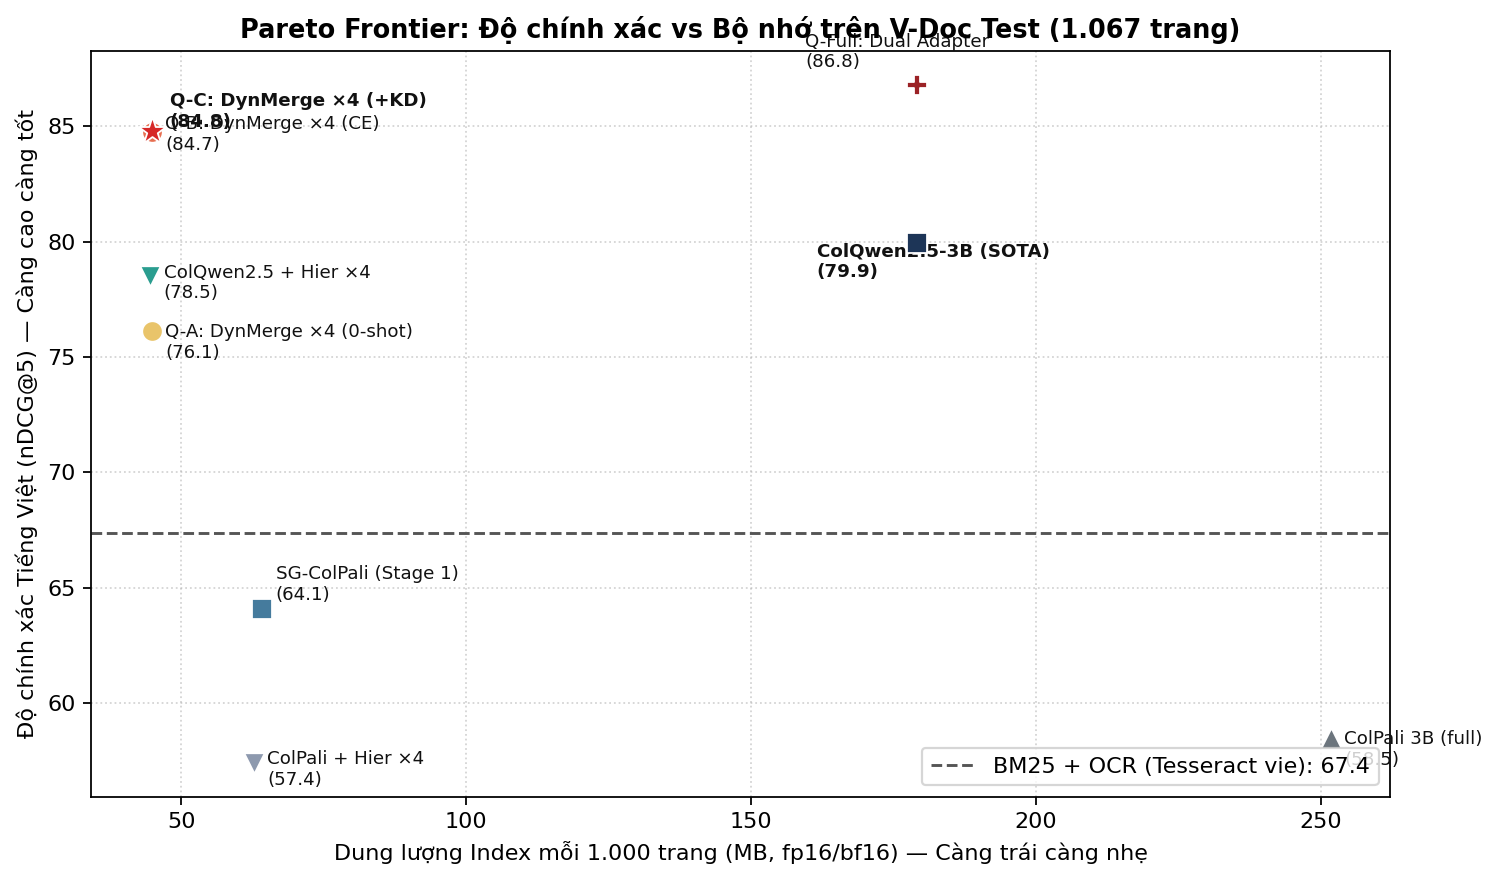

In [ ]:
REF_QWEN = "SOTA: ColQwen2.5-3B (zero-shot)"
REF_HIER = "ColQwen2.5 + Hierarchical pooling ×4 (không train, CPU)"
REF_BM25 = "BM25 + OCR (Tesseract vie)"
pq = lambda v, k="nDCG@5": np.mean([per_query(r, k) for r in np.atleast_2d(v)], 0)

PREFERRED_ORDER = [
    REF_BM25,
    "ColPali 3B đầy đủ (zero-shot)",
    "Hierarchical pooling ×4 (không train, CPU)",
    "Full SG-ColPali (cổng + KD)",
    "SOTA: ColVintern-1B-v1 (zero-shot)",
    REF_QWEN,
    REF_HIER,
    "Q-A: ColQwen2.5 + DynMerge ×4 (chưa train, GPU)",
    "Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure CE, V-Doc)",
    "Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD & Anchor, V-Doc)",
    "Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+ KD & Anchor, V-Doc)",
    "Q-C-Mix: DynMerge ×4 + Adapter (+ KD, V-Doc + 5CD-AI)",
    "Q-Full-Mix: ColQwen2.5 (733 vec) + Dual Adapter (+ KD, V-Doc + 5CD-AI)",
]
ordered_names = [n for n in PREFERRED_ORDER if n in RESULTS] + [n for n in RESULTS if n not in PREFERRED_ORDER]

rows = []
for name in ordered_names:
    v = RESULTS[name]
    R = np.atleast_2d(v["vi"])
    dim = int(v.get("embed_dim") or 128)
    vpp = v.get("vec_per_page")
    row = {
        "Mô hình": name,
        "Dim": dim if vpp else None,
        "Vec/trang": round(float(vpp), 1) if vpp else None,
        "MB/1000 trang": round(MB_PER_1K(float(vpp), dim), 1) if vpp else None,
    }
    for k in KEYS[:3]:
        s = [metrics(r)[k] for r in R]
        row[f"VI {k}"] = f"{np.mean(s):.1f}" + (f" ± {np.std(s):.1f}" if len(s) > 1 else "")
    lo, hi = np.percentile(boot(pq(v["vi"])), [2.5, 97.5])
    row["nDCG@5 CI95"] = f"[{lo:.1f}, {hi:.1f}]"

    for ref, col in [(REF_QWEN, "p vs ColQwen2.5"), (REF_HIER, "p vs Hier ×4"), (REF_BM25, "p vs BM25")]:
        if ref in RESULTS and name != ref:
            d = boot(pq(v["vi"]) - pq(RESULTS[ref]["vi"]))
            row[col] = round(float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))), 4)
        else:
            row[col] = None

    row["EN DocVQA nDCG@5"] = round(float(np.mean([metrics(r)["nDCG@5"] for r in np.atleast_2d(v["en"])])), 1) if v.get("en") else None
    dev_str = v.get("device", "")
    if v.get("encode_s_per_page") is not None:
        row["Thời gian"] = f"{v['encode_s_per_page']:.2f} s/trang encode ({dev_str})"
    elif v.get("ms_per_page") is not None:
        row["Thời gian"] = f"{v['ms_per_page']:.2f} ms/trang ({dev_str})"
    else:
        row["Thời gian"] = None
    rows.append(row)

df_master = pd.DataFrame(rows)
df_master.to_csv(f"{SAVE_DIR}/results_stage2_master.csv", index=False)
display(df_master)

# ---- Slice Analysis trên bộ Test 1.067 trang ----
if RUN_SLICE_ANALYSIS and OCR_TEXTS is not None and len(OCR_TEXTS) == len(TEST_Q):
    ocr_lens = np.array([len(t.strip()) for t in OCR_TEXTS])
    has_cue = np.array([bool(re.search(r"\b(hình|bảng|ví dụ|biểu đồ|sơ đồ|câu|bài)\s*\d", q.lower())) for q in TEST_Q])
    slices = {
        f"Tất cả ({len(TEST_Q)})": np.ones(len(TEST_Q), dtype=bool),
        f"OCR ít (<200, n={(ocr_lens < 200).sum()})": ocr_lens < 200,
        f"OCR vừa (200–800, n={((ocr_lens >= 200) & (ocr_lens <= 800)).sum()})": (ocr_lens >= 200) & (ocr_lens <= 800),
        f"OCR dày (>800, n={(ocr_lens > 800).sum()})": ocr_lens > 800,
        f"Có nhãn số (n={has_cue.sum()})": has_cue,
        f"Không nhãn số (n={(~has_cue).sum()})": ~has_cue,
    }
    slice_cands = [
        REF_BM25,
        "ColPali 3B đầy đủ (zero-shot)",
        "Full SG-ColPali (cổng + KD)",
        "SOTA: ColVintern-1B-v1 (zero-shot)",
        REF_QWEN,
        REF_HIER,
        "Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD & Anchor, V-Doc)",
        "Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+ KD & Anchor, V-Doc)",
        "Q-C-Mix: DynMerge ×4 + Adapter (+ KD, V-Doc + 5CD-AI)",
        "Q-Full-Mix: ColQwen2.5 (733 vec) + Dual Adapter (+ KD, V-Doc + 5CD-AI)",
    ]
    slice_rows = []
    for m_name in [m for m in slice_cands if m in RESULTS]:
        q_scores = pq(RESULTS[m_name]["vi"], "nDCG@5")
        s_row = {"Mô hình": m_name}
        for s_label, mask in slices.items():
            s_row[s_label] = round(float(q_scores[mask].mean()), 1) if mask.any() else None
        slice_rows.append(s_row)
    df_slice = pd.DataFrame(slice_rows)
    df_slice.to_csv(f"{SAVE_DIR}/slice_analysis_stage2.csv", index=False)
    print("\n--- Slice Analysis (VI nDCG@5 theo mật độ chữ & kiểu câu hỏi) ---")
    display(df_slice)

# ---- Biểu đồ Pareto Frontier (MB/1000 trang vs VI nDCG@5) ----
if RUN_PLOT:
    fig, ax = plt.subplots(figsize=(9.5, 5.6), dpi=160)
    if REF_BM25 in RESULTS:
        bm25_nd = float(np.mean([metrics(r)["nDCG@5"] for r in np.atleast_2d(RESULTS[REF_BM25]["vi"])]))
        ax.axhline(bm25_nd, linestyle="--", color="#555555", linewidth=1.3, label=f"BM25 + OCR (Tesseract vie): {bm25_nd:.1f}")

    LABEL_SHORT = {
        "ColPali 3B đầy đủ (zero-shot)": ("ColPali 3B (full)", "#6c757d", "^", (6, -12)),
        "Hierarchical pooling ×4 (không train, CPU)": ("ColPali + Hier ×4", "#8d99ae", "v", (6, -10)),
        "Full SG-ColPali (cổng + KD)": ("SG-ColPali (Stage 1)", "#457b9d", "s", (6, 4)),
        "SOTA: ColVintern-1B-v1 (zero-shot)": ("ColVintern-1B", "#f4a261", "D", (6, -10)),
        REF_QWEN: ("ColQwen2.5-3B (SOTA)", "#1d3557", "s", (-45, -15)),
        REF_HIER: ("ColQwen2.5 + Hier ×4", "#2a9d8f", "v", (6, -10)),
        "Q-A: ColQwen2.5 + DynMerge ×4 (chưa train, GPU)": ("Q-A: DynMerge ×4 (0-shot)", "#e9c46a", "o", (6, -12)),
        "Q-B: ColQwen2.5 + DynMerge ×4 + Adapter (Pure CE, V-Doc)": ("Q-B: DynMerge ×4 (CE)", "#e76f51", "o", (6, -8)),
        "Q-C: ColQwen2.5 + DynMerge ×4 + Adapter (+ KD & Anchor, V-Doc)": ("Q-C: DynMerge ×4 (+KD)", "#d62828", "*", (8, 2)),
        "Q-Full: ColQwen2.5 (733 vec) + Dual Adapter (+ KD & Anchor, V-Doc)": ("Q-Full: Dual Adapter", "#9b2226", "P", (-50, 8)),
        "Q-C-Mix: DynMerge ×4 + Adapter (+ KD, V-Doc + 5CD-AI)": ("Q-C-Mix (Đa miền)", "#b5179e", "*", (8, -12)),
        "Q-Full-Mix: ColQwen2.5 (733 vec) + Dual Adapter (+ KD, V-Doc + 5CD-AI)": ("Q-Full-Mix (Đa miền)", "#7209b7", "P", (-55, -14)),
    }

    for name in ordered_names:
        v = RESULTS[name]
        vpp = v.get("vec_per_page")
        if not vpp:
            continue
        dim = int(v.get("embed_dim") or 128)
        mb = MB_PER_1K(float(vpp), dim)
        nd = float(np.mean([metrics(r)["nDCG@5"] for r in np.atleast_2d(v["vi"])]))
        if name in LABEL_SHORT:
            short, col, mk, offset = LABEL_SHORT[name]
            sz = 170 if mk == "*" else 85
            ax.scatter(mb, nd, color=col, marker=mk, s=sz, zorder=4, edgecolors="white", linewidths=0.8)
            ax.annotate(f"{short}\n({nd:.1f})", (mb, nd), xytext=offset, textcoords="offset points",
                        fontsize=8.2, fontweight="bold" if col in ("#d62828", "#b5179e", "#1d3557") else "normal", color="#111111")

    ax.set_xlabel("Dung lượng Index mỗi 1.000 trang (MB, fp16/bf16) — Càng trái càng nhẹ", fontsize=10)
    ax.set_ylabel("Độ chính xác Tiếng Việt (nDCG@5) — Càng cao càng tốt", fontsize=10)
    ax.set_title("Pareto Frontier: Độ chính xác vs Bộ nhớ trên V-Doc Test (1.067 trang)", fontsize=11.5, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.55)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="lower right", frameon=True)
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/pareto_stage2.png", dpi=200)
    plt.show()

## 9. Checklist Đọc Kết Quả & Chuẩn Bị Slide Thuyết Trình 4–5 Phút

Sau khi chạy xong Cell 18, các kết quả quan trọng cần kiểm tra:
1. **Thắng SOTA về Trade-off (`Q-C` / `Q-C-Mix` vs `ColQwen2.5` & `Hier ×4`):**
   - Bộ nhớ index giảm **~4 lần** (`179.0 MB → ~45 MB / 1.000 trang`), nén trên GPU chỉ tốn `< 0.2 ms/trang` (so với CPU `Hierarchical pooling`), mà vẫn giữ hoặc vượt điểm SOTA `79.9` (`p vs Hier ×4 < 0.05` và không giảm / vượt trên `EN DocVQA`).
2. **Thắng SOTA về trần Tiếng Việt (`Q-Full` / `Q-Full-Mix` vs `ColQwen2.5` `79.9`):**
   - Đẩy trần tiếng Việt vượt rõ mốc zero-shot `79.9` với chỉ `~52K` tham số (không cần fine-tune LoRA VLM 3B) và `p vs ColQwen2.5 < 0.05`.
3. **Giá trị của Data Mixture sạch (`Q-C-Mix` vs `Q-C`):**
   - Xem việc bổ sung `5CD-AI` (đã lọc 5 lớp chống leakage, loại bỏ `docvqa` & hash trùng) có giúp giữ tốt hơn `EN DocVQA` hoặc cải thiện các trang ngoài sách giáo khoa hay không.
4. **Bằng chứng định tính (`Cell 16`):**
   - Kiểm tra hệ số tương quan `Pearson r` vị trí–trọng số của `Query Gate` đã tiến về gần `0` (sửa triệt để bias `<bos>`/`"Trong"` ở Giai đoạn 1).